# Survival after pediatric bone-marrow transplantation

Lukas Juranek · Lab II · November 2026

187 children received an unrelated-donor transplant. Eighty-five died, and 102 were still alive at last contact. The file asks whether a higher CD34+ cell dose is associated with longer survival. This notebook also asks whether the measurements known at transplant form groups with different survival, and whether Kaplan–Meier and Cox regression agree.

The report is `report/report.pdf`. The figures saved below are the ones in that report.


## Data

The source is `bone-marrow.arff`. A `?` is a missing value. `survival_time` is days from transplant. `survival_status` is 1 if the child died and 0 if the child was last seen alive.


In [1]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings(
    "ignore",
    message="DataFrame Index is not unique, defaulting to incrementing index instead.",
)

ROOT = Path.cwd().resolve()
if not (ROOT / "bone-marrow.arff").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from bmt.data import clean, load_arff, validate

pd.set_option("display.max_columns", 24)
pd.set_option("display.width", 110)
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
    "font.size": 11,
})


def p_text(p):
    if pd.isna(p):
        return ""
    return f"{p:.1e}" if p < 0.001 else f"{p:.3f}"


raw = load_arff(ROOT / "bone-marrow.arff")
validate(raw)
df = clean(raw)

deaths = int(df["survival_status"].sum())
print(f"{len(df)} patients, {deaths} deaths, {len(df) - deaths} censored")
print(f"Follow-up {int(df['survival_time'].min())} to {int(df['survival_time'].max())} days")

preview = [
    "Recipientage", "Rbodymass", "Donorage", "Disease", "Riskgroup",
    "Stemcellsource", "CD34kgx10d6", "HLAmatch",
    "survival_time", "survival_status",
]
look = df[preview].head(8).copy()
look["Donorage"] = look["Donorage"].round(1)
display(look)
display(
    df["Disease"].value_counts().rename_axis("Disease").reset_index(name="Patients")
)


187 patients, 85 deaths, 102 censored
Follow-up 6 to 3364 days


,Recipientage,Rbodymass,Donorage,Disease,Riskgroup,Stemcellsource,CD34kgx10d6,HLAmatch,survival_time,survival_status
0,9.6,35.0,22.8,ALL,1,1,7.20,0,999,0
1,4.0,20.6,23.3,ALL,0,0,4.50,0,163,1
2,6.6,23.4,26.4,ALL,0,0,7.94,0,435,1
3,18.1,50.0,39.7,AML,0,0,4.25,0,53,1
4,1.3,9.0,33.4,chronic,1,1,51.85,1,2043,0
5,8.9,40.0,27.4,chronic,1,0,3.27,0,2800,0
6,14.4,51.0,34.5,AML,0,1,17.78,0,41,1
7,18.2,56.0,21.4,nonmalignant,0,0,6.41,3,45,1


,Disease,Patients
0,ALL,68
1,chronic,45
2,AML,33
3,nonmalignant,32
4,lymphoma,9


## Exclusions

The models use only what is known at transplant. Relapse, graft-versus-host disease, and the times to neutrophil recovery, platelet recovery, and severe acute GvHD come later, so they stay out. Those three time columns store `1000000` when the event was never observed. In `aGvHDIIIIV` and `extcGvHD`, the code 0 means yes.

A missing value is not harmless. Extensive chronic GvHD is often blank because the child died before it could be recorded, so “any missing field” looks strongly related to death. The comparison that matters for modeling is missingness among the baseline fields only.


,Column,Missing,Percent
0,extcGvHD,31,16.58
1,CMVstatus,16,8.56
2,RecipientCMV,14,7.49
3,CD3dCD34,5,2.67
4,CD3dkgx10d8,5,2.67
5,DonorCMV,2,1.07
6,Rbodymass,2,1.07
7,RecipientRh,2,1.07
8,ABOmatch,1,0.53
9,Alel,1,0.53


,Column,Sentinel 1000000,Also died
0,ANCrecovery,5,5
1,PLTrecovery,17,17
2,time_to_aGvHD_III_IV,145,62


Any missing field: 45 patients, log-rank p = 8.5e-21
Baseline fields only: 23 patients, log-rank p = 0.006


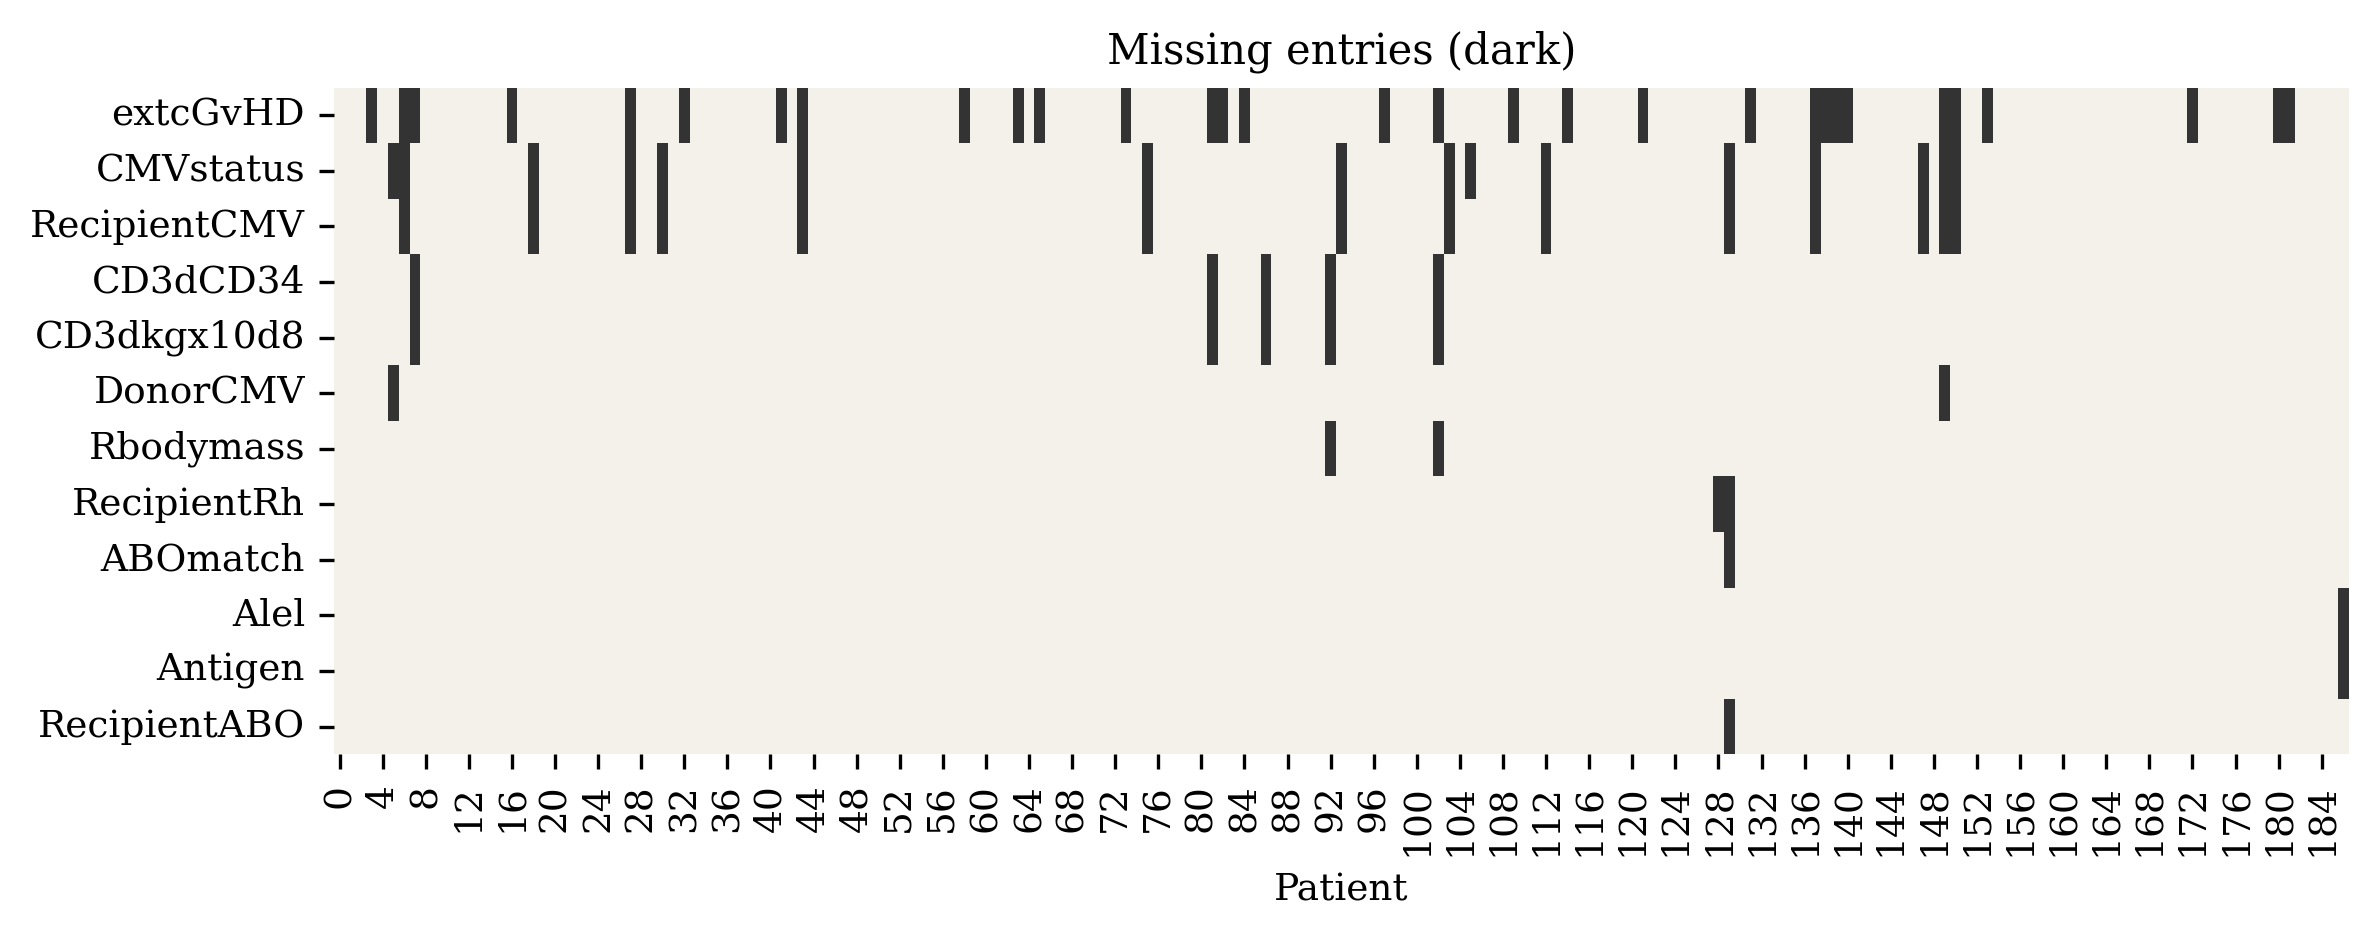

In [2]:
from bmt.data import OUTCOMES, POST_TRANSPLANT, any_missing_mask, missingness_table, sentinel_table
from bmt.plots import plot_missingness
from bmt.survival import logrank

missing = missingness_table(raw).rename(columns={
    "column": "Column",
    "n_missing": "Missing",
    "pct_missing": "Percent",
})
sentinels = sentinel_table(raw).rename(columns={
    "column": "Column",
    "n_sentinel": "Sentinel 1000000",
    "n_sentinel_and_death": "Also died",
})
display(missing)
display(sentinels)

time = df["survival_time"]
event = df["survival_status"]
missing_flag = any_missing_mask(raw).astype(int)
baseline_cols = [c for c in raw.columns if c not in POST_TRANSPLANT + OUTCOMES]
baseline_missing = raw[baseline_cols].isna().any(axis=1).astype(int)

any_lr = logrank(time, event, missing_flag.reset_index(drop=True))
base_lr = logrank(time, event, baseline_missing.reset_index(drop=True))
print(f"Any missing field: {int(missing_flag.sum())} patients, log-rank p = {p_text(any_lr.p_value)}")
print(f"Baseline fields only: {int(baseline_missing.sum())} patients, log-rank p = {p_text(base_lr.p_value)}")

plot_missingness(raw, list(missing["Column"]), ROOT / "figures" / "missingness.pdf")
display(Image(filename=str(ROOT / "figures" / "missingness.png"), width=760))


## Overall survival

The curve is Kaplan–Meier. Median follow-up treats censoring as the event (reverse Kaplan–Meier), because the ordinary median of the recorded times would treat a short look at a survivor as a short life.


Median survival: not reached
Median follow-up: 1522 days


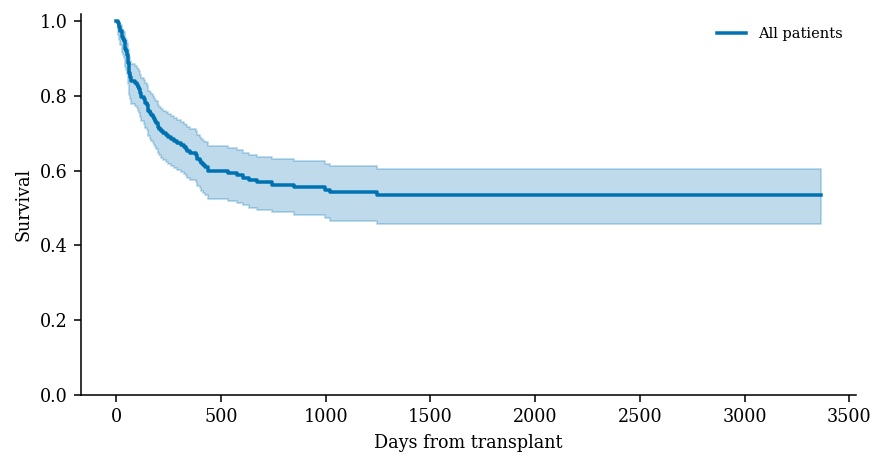

In [3]:
from bmt.survival import fit_km, reverse_km_median_followup
from lifelines import KaplanMeierFitter

km = fit_km(time, event, label="All patients")
followup = reverse_km_median_followup(time, event)
median = float(km.median_survival_time_)
median_txt = "not reached" if np.isinf(median) else f"{median:.0f} days"
print(f"Median survival: {median_txt}")
print(f"Median follow-up: {followup:.0f} days")

fig, ax = plt.subplots(figsize=(6.4, 3.4))
km.plot_survival_function(ax=ax, ci_show=True, color="#0072B2", linewidth=1.8)
ax.set_xlabel("Days from transplant")
ax.set_ylabel("Survival")
ax.set_ylim(0, 1.02)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


## One feature at a time

Each baseline feature gets its own Cox model. Disease is compared with ALL. The Pearson column correlates the feature with the recorded time and ignores censoring. It is there to show where that shortcut disagrees with the Cox model. The forest plot is the ten smallest Cox p-values.


,Feature,n,Deaths,HR,Low,High,p
0,Rbodymass,185,83,1.021,1.010,1.033,3.0e-04
1,Disease[lymphoma vs ALL],187,85,3.870,1.827,8.196,4.1e-04
2,CD3dkgx10d8,182,81,0.901,0.842,0.964,0.002
3,Recipientage,187,85,1.067,1.022,1.113,0.003
4,CD34kgx10d6,187,85,0.971,0.945,0.998,0.035
5,Recipientage10,187,85,1.580,1.030,2.424,0.036
6,Stemcellsource,187,85,0.626,0.390,1.004,0.052
7,Recipientageint,187,85,1.303,0.992,1.713,0.057
8,Donorage35,187,85,1.487,0.971,2.276,0.068
9,Riskgroup,187,85,1.461,0.952,2.240,0.083


,Feature,Pearson r,Cox HR,Cox p
0,Rbodymass,-0.15,1.02,3.0e-04
1,Txpostrelapse,0.00,1.40,0.253
2,CD34kgx10d6,0.14,0.97,0.035
3,Stemcellsource,-0.04,0.63,0.052
4,Donorage35,-0.04,1.49,0.068
5,Gendermatch,-0.11,1.06,0.846


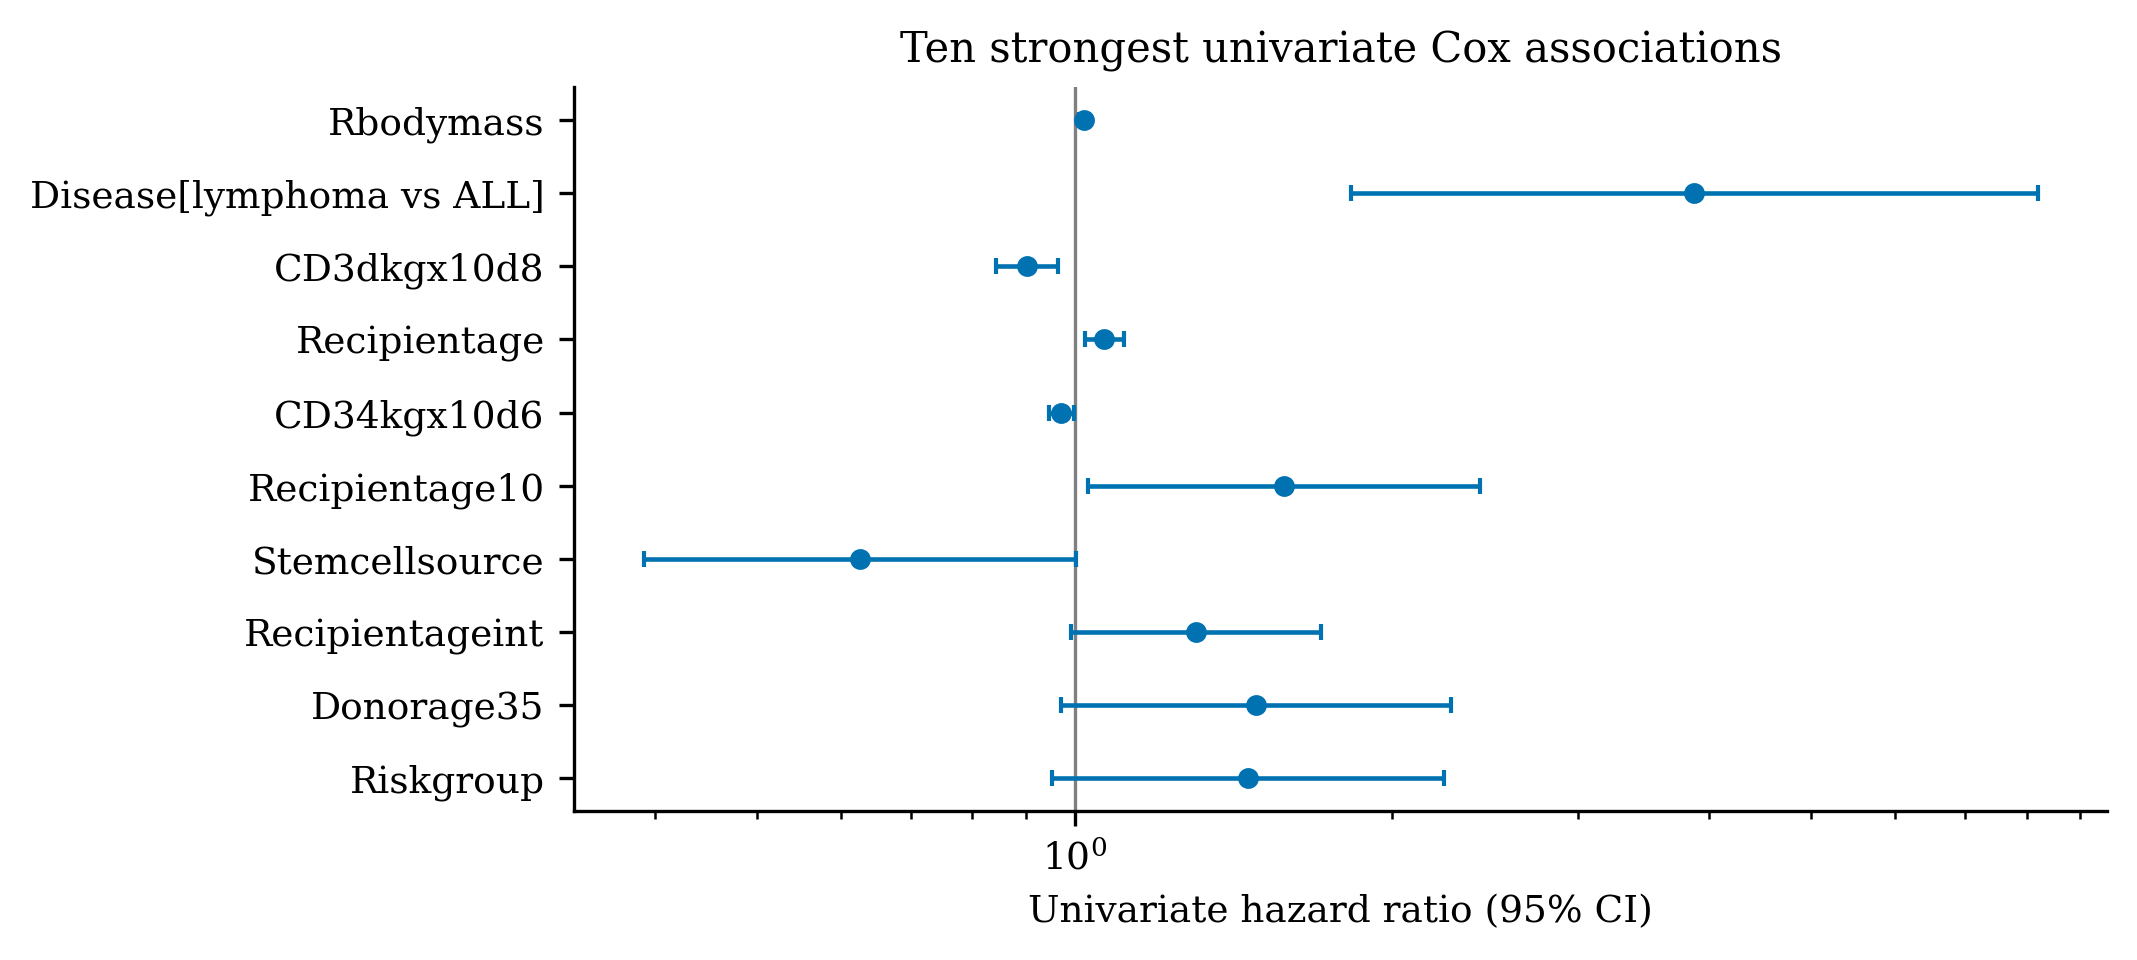

In [4]:
from bmt.data import SCREEN_BINARY, SCREEN_NUMERIC, SCREEN_ORDINAL
from bmt.features import pearson_with_time
from bmt.plots import plot_fig4
from bmt.survival import univariate_screen

univariate = univariate_screen(df)
top = univariate.head(10)[["feature", "n", "events", "hr", "hr_low", "hr_high", "p"]].copy()
for col in ("hr", "hr_low", "hr_high"):
    top[col] = top[col].map(lambda v: f"{v:.3f}")
top["p"] = top["p"].map(p_text)
display(top.rename(columns={
    "feature": "Feature",
    "n": "n",
    "events": "Deaths",
    "hr": "HR",
    "hr_low": "Low",
    "hr_high": "High",
}))

pearson = pearson_with_time(df, SCREEN_NUMERIC + SCREEN_BINARY + SCREEN_ORDINAL)
contrast = pearson.merge(univariate[["feature", "hr", "p", "log_hr"]], on="feature", how="left")
contrast["gap"] = (
    contrast["pearson_r"].abs().rank(ascending=False, method="min")
    - contrast["log_hr"].abs().rank(ascending=False, method="min")
)
show = (
    contrast.reindex(contrast["gap"].abs().sort_values(ascending=False).index)
    .head(6)
    .reset_index(drop=True)
)
show = show[["feature", "pearson_r", "hr", "p"]].copy()
show["pearson_r"] = show["pearson_r"].map(lambda v: f"{v:.2f}")
show["hr"] = show["hr"].map(lambda v: f"{v:.2f}")
show["p"] = show["p"].map(p_text)
display(show.rename(columns={
    "feature": "Feature",
    "pearson_r": "Pearson r",
    "hr": "Cox HR",
    "p": "Cox p",
}))

plot_fig4(univariate, ROOT / "figures" / "fig4_univariate.pdf")
display(Image(filename=str(ROOT / "figures" / "fig4_univariate.png"), width=680))


## Repeated measurements

Age is stored as a number and as two bins. HLA, ABO, CMV, and cell dose are blocks of overlapping columns. Body mass tracks age, so the Cox model keeps age and leaves body mass out. Variance inflation for the eight Cox covariates is below 2.2.


Spearman, recipient age and body mass: 0.933


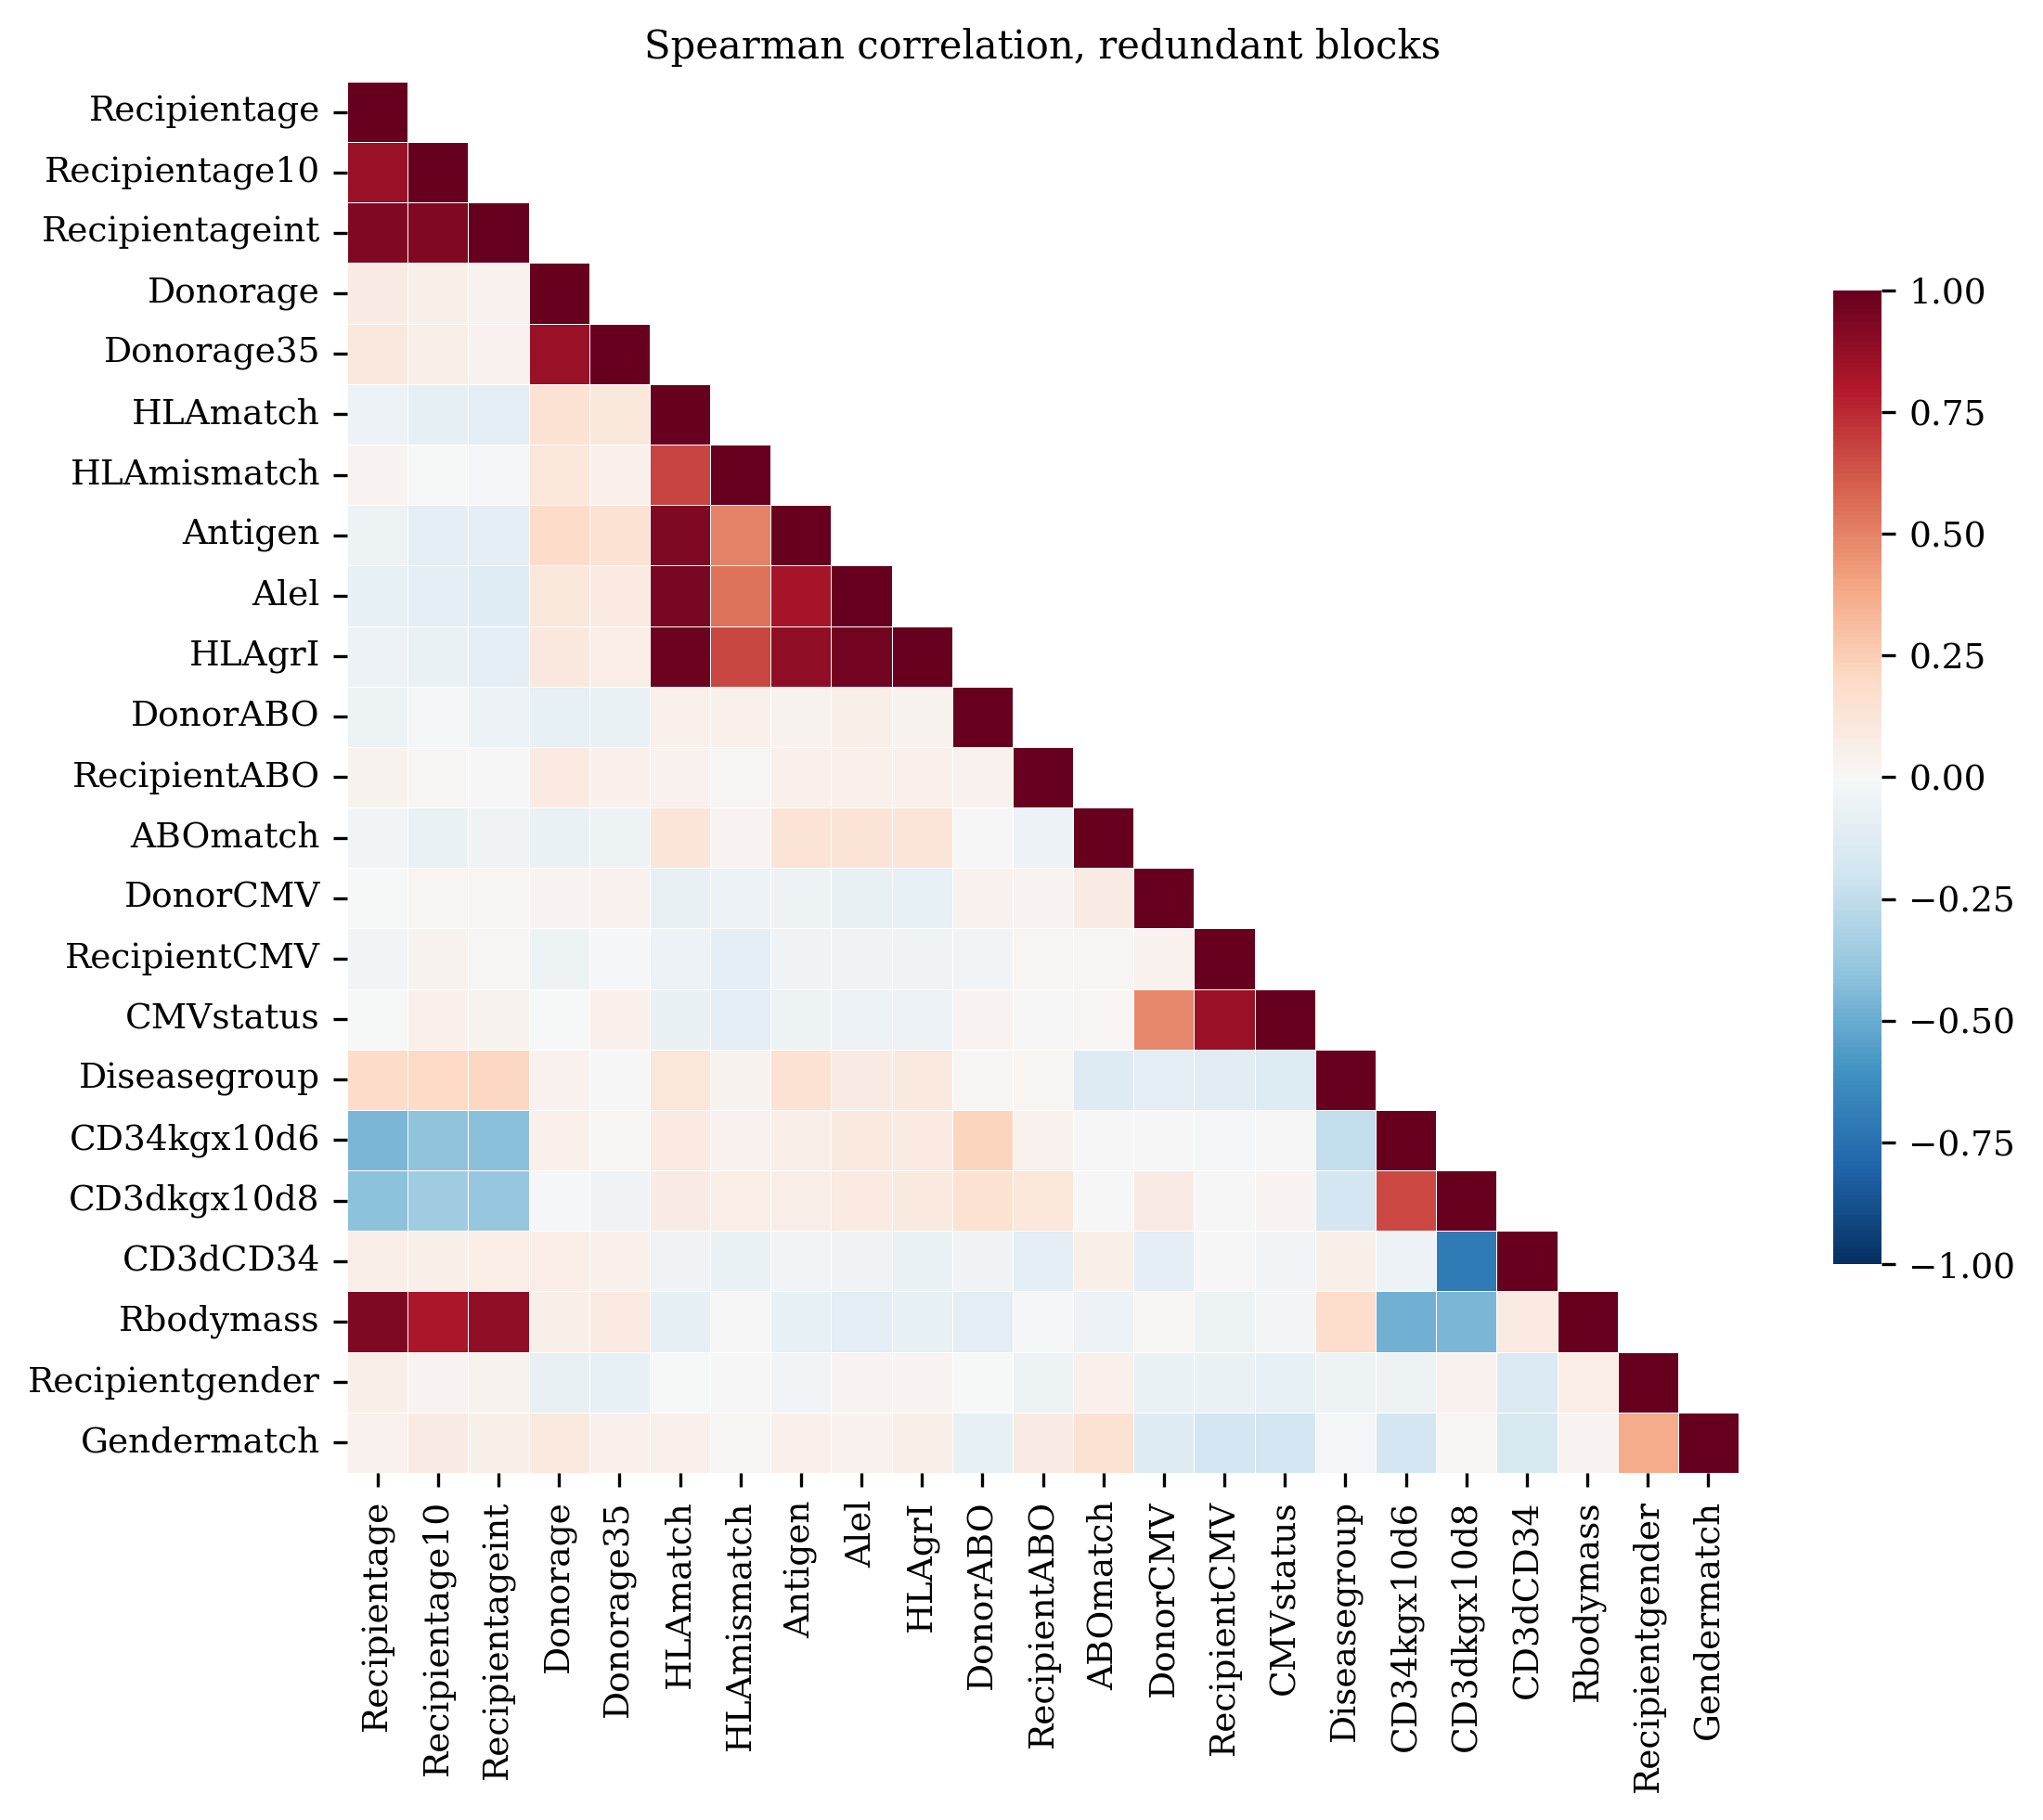

,Covariate,VIF
0,log CD34+ dose (per kg),2.13
1,Peripheral-blood stem cells,1.69
2,High risk,1.46
3,Second transplant after relapse,1.37
4,Recipient age (per 5 years),1.36
5,Malignant disease,1.14
6,HLA mismatch (8/10 or 7/10),1.06
7,Donor age (per 10 years),1.03


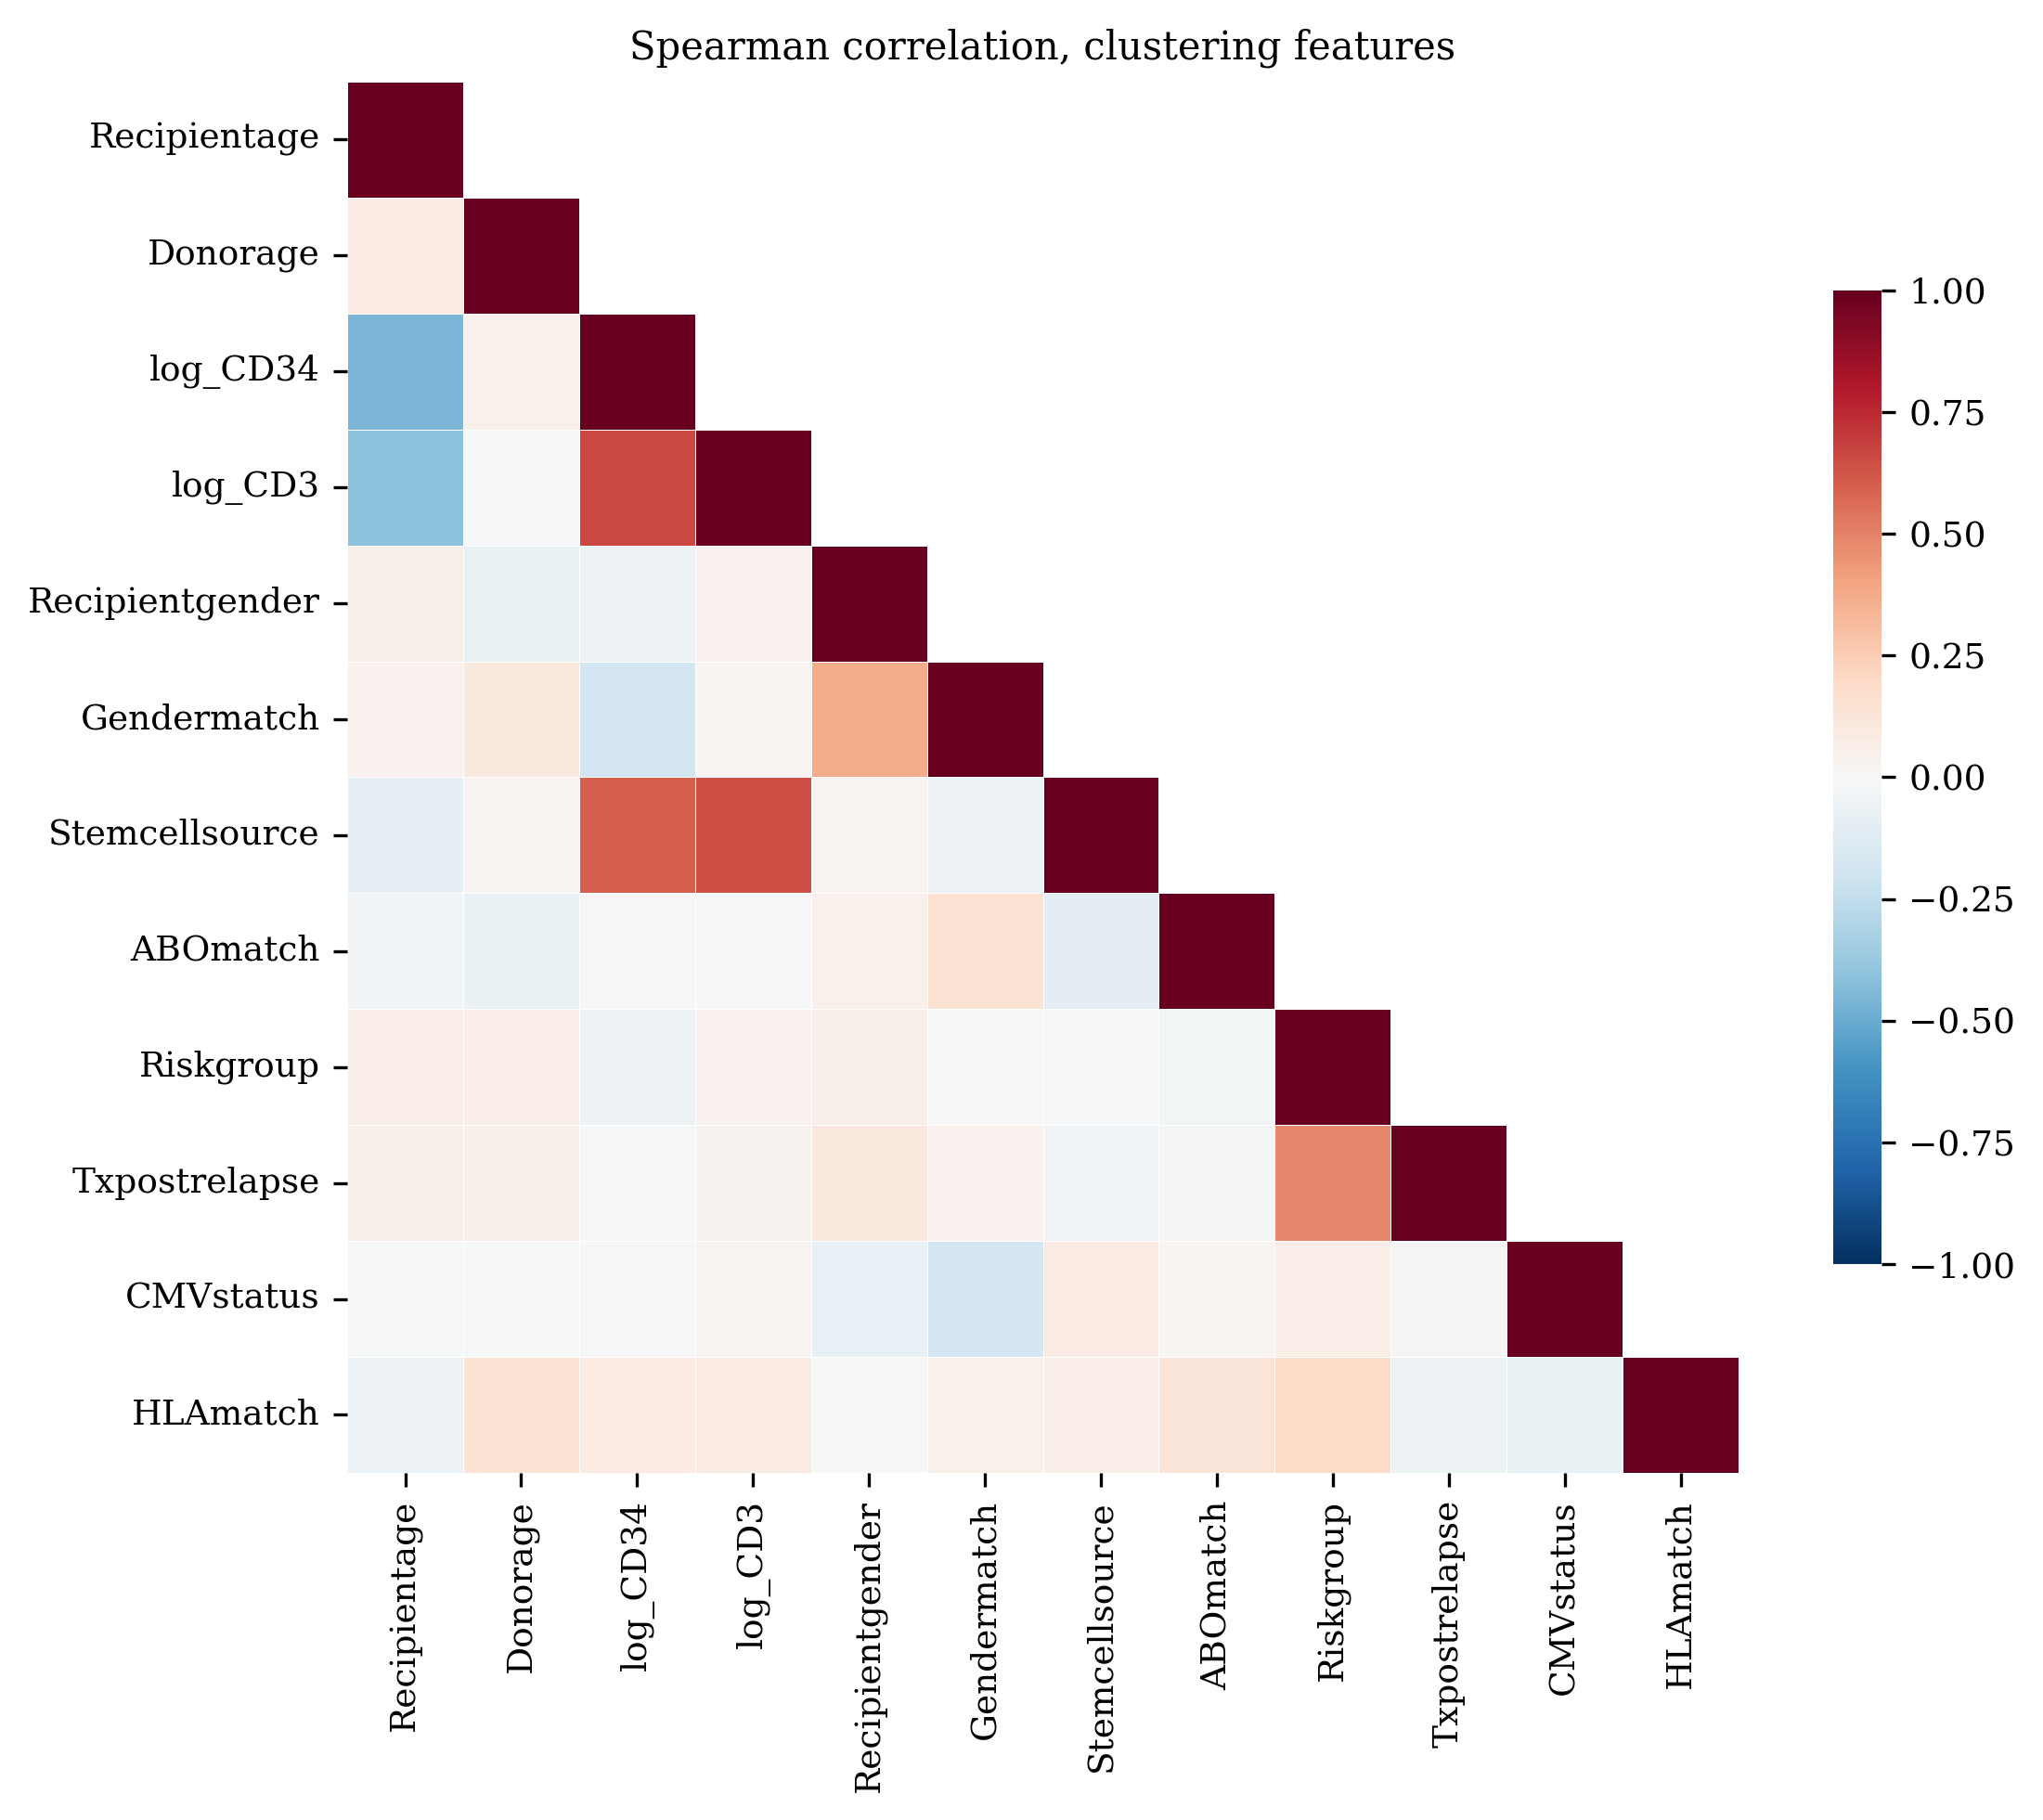

In [5]:
from bmt.data import REDUNDANT_GROUPS
from bmt.features import (
    CLUSTER_BINARY,
    CLUSTER_NUMERIC,
    CLUSTER_ORDINAL,
    COX_LABELS,
    impute_numeric,
    spearman_matrix,
    vif_table,
)
from bmt.plots import plot_spearman

rho = df[["Recipientage", "Rbodymass"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman, recipient age and body mass: {rho:.3f}")

wide_cols = [c for cols in REDUNDANT_GROUPS.values() for c in cols if c != "Disease"]
spearman_wide = spearman_matrix(df, wide_cols)
plot_spearman(
    spearman_wide,
    ROOT / "figures" / "spearman_blocks.pdf",
    "Spearman correlation, redundant blocks",
)
display(Image(filename=str(ROOT / "figures" / "spearman_blocks.png"), width=640))

cox = pd.DataFrame({
    "Recipientage_per5": df["Recipientage"] / 5,
    "Donorage_per10": df["Donorage"] / 10,
    "log_CD34": df["log_CD34"],
    "Diseasegroup": df["Diseasegroup"],
    "Riskgroup": df["Riskgroup"],
    "Txpostrelapse": df["Txpostrelapse"],
    "HLAmismatch": df["HLAmismatch"],
    "Stemcellsource": df["Stemcellsource"],
})
cox_imputed, _ = impute_numeric(cox, cox)
vifs = vif_table(cox_imputed)
vifs["Covariate"] = vifs["feature"].map(lambda name: COX_LABELS.get(name, name))
vifs["VIF"] = vifs["vif"].map(lambda v: f"{v:.2f}")
display(vifs[["Covariate", "VIF"]])

spearman = spearman_matrix(df, CLUSTER_NUMERIC + CLUSTER_BINARY + CLUSTER_ORDINAL)
plot_spearman(
    spearman,
    ROOT / "figures" / "spearman_cluster.pdf",
    "Spearman correlation, clustering features",
)
display(Image(filename=str(ROOT / "figures" / "spearman_cluster.png"), width=640))


## Groups

Thirteen inputs: recipient age, donor age, log CD34, log CD3, recipient sex, sex match, graft source, ABO match, risk group, second transplant, CMV status, HLA match, and disease. Continuous columns are median-imputed, codes take the most frequent value, disease is one-hot encoded, and every column is standardized.

Principal components keep 85% of the variance. K-means is fit for K from 2 to 8, with 50 restarts and seed 42. The chosen K has the highest silhouette among solutions whose smallest group has at least 15 patients. DBSCAN is fit on the same components as a check: neighborhood size is twice the number of components, and epsilon is the knee of the sorted k-distance curve.


,K,Silhouette,Smallest,Largest,Eligible
0,2,0.174,44,143,yes
1,3,0.131,43,72,yes
2,4,0.154,31,68,yes
3,5,0.184,31,46,yes
4,6,0.215,9,48,no
5,7,0.223,9,47,no
6,8,0.222,9,44,no


11 components, 88.6% of variance. K = 5.
First two components: 15.7% and 11.5%.


,Group,Description,n,Deaths,Median days,Mean age,CD34,Peripheral blood
0,0,"ALL, low-risk",46,17,not reached,9.1,10.1,100%
1,1,"chronic, poorer HLA match",36,17,not reached,9.2,11.5,94%
2,2,"mostly marrow, lower CD34",38,22,421,11.5,2.9,8%
3,3,"AML, often post-relapse",36,18,1243,11.9,10.2,97%
4,4,"nonmalignant, younger recipients",31,11,not reached,7.7,16.0,87%


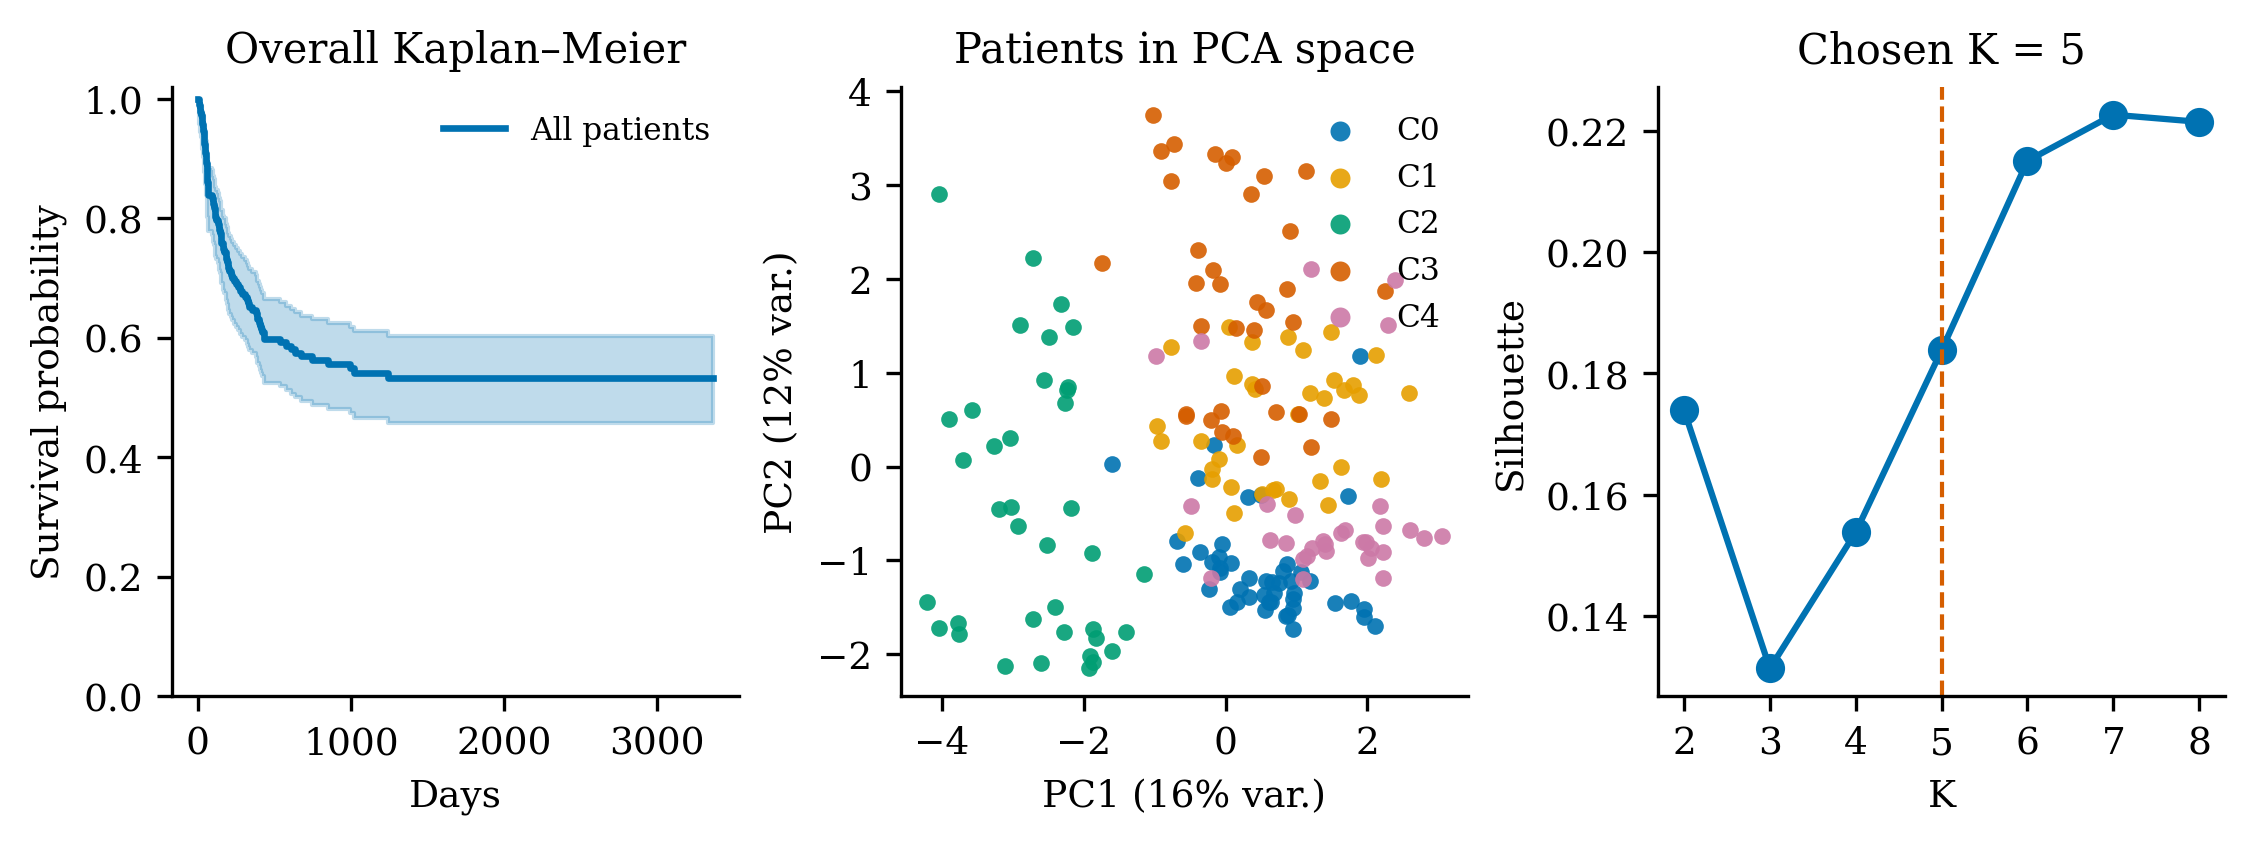

DBSCAN: eps = 5.58, min_samples = 22, 1 cluster, 0 noise points, ARI against K-means = 0.00.


In [6]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

from bmt.clustering import profile_clusters, run_dbscan
from bmt.features import fit_cluster_matrix
from bmt.plots import plot_fig1

scaled, _ = fit_cluster_matrix(df)
pca = PCA(n_components=0.85, svd_solver="full", random_state=42)
scores = pca.fit_transform(scaled)
pca_2d = PCA(n_components=2, svd_solver="full", random_state=42)
scores_2d = pca_2d.fit_transform(scaled)
var_2d = pca_2d.explained_variance_ratio_

rows = []
fitted = {}
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=50, random_state=42)
    lab = model.fit_predict(scores)
    sizes = np.bincount(lab)
    rows.append({
        "k": k,
        "silhouette": float(silhouette_score(scores, lab)),
        "min_size": int(sizes.min()),
        "max_size": int(sizes.max()),
        "eligible": bool(sizes.min() >= 15),
    })
    fitted[k] = lab

k_table = pd.DataFrame(rows)
eligible = k_table[k_table["eligible"]].sort_values(["silhouette", "k"], ascending=[False, True])
chosen_k = int(eligible.iloc[0]["k"])
labels = fitted[chosen_k]

k_view = k_table.copy()
k_view["silhouette"] = k_view["silhouette"].map(lambda v: f"{v:.3f}")
k_view["eligible"] = k_view["eligible"].map(lambda v: "yes" if v else "no")
display(k_view.rename(columns={
    "k": "K",
    "silhouette": "Silhouette",
    "min_size": "Smallest",
    "max_size": "Largest",
    "eligible": "Eligible",
}))
print(
    f"{pca.n_components_} components, {100 * pca.explained_variance_ratio_.sum():.1f}% of variance. "
    f"K = {chosen_k}."
)
print(f"First two components: {100 * var_2d[0]:.1f}% and {100 * var_2d[1]:.1f}%.")

profile = profile_clusters(df, labels)
names = {int(row.cluster): row.name for row in profile.itertuples(index=False)}
prof = profile[[
    "cluster", "name", "n", "events", "median_survival_days",
    "Recipientage_mean", "CD34_median", "pct_pbsc",
]].copy()
prof["median_survival_days"] = prof["median_survival_days"].map(
    lambda v: "not reached" if np.isinf(v) else f"{v:.0f}"
)
prof["Recipientage_mean"] = prof["Recipientage_mean"].map(lambda v: f"{v:.1f}")
prof["CD34_median"] = prof["CD34_median"].map(lambda v: f"{v:.1f}")
prof["pct_pbsc"] = prof["pct_pbsc"].map(lambda v: f"{100 * v:.0f}%")
display(prof.rename(columns={
    "cluster": "Group",
    "name": "Description",
    "n": "n",
    "events": "Deaths",
    "median_survival_days": "Median days",
    "Recipientage_mean": "Mean age",
    "CD34_median": "CD34",
    "pct_pbsc": "Peripheral blood",
}))

plot_fig1(
    time, event, scores_2d, var_2d, labels, names, k_table, chosen_k,
    ROOT / "figures" / "fig1_overview.pdf",
)
display(Image(filename=str(ROOT / "figures" / "fig1_overview.png"), width=860))

db = run_dbscan(scores, labels)
print(
    f"DBSCAN: eps = {db['eps']:.2f}, min_samples = {db['min_samples']}, "
    f"{db['n_clusters']} cluster, {db['n_noise']} noise points, "
    f"ARI against K-means = {db['ari_vs_kmeans']:.2f}."
)


## Kaplan–Meier by group

One curve per K-means group. The log-rank test asks whether the curves differ. Pairwise p-values are Bonferroni-corrected because there are ten pairs.


Log-rank χ² = 5.41 on 4 df, p = 0.248


,Group,versus,p,Bonferroni
0,0,1,0.409,1.000
1,0,2,0.049,0.487
2,0,3,0.345,1.000
3,0,4,0.895,1.000
4,1,2,0.260,1.000
5,1,3,0.898,1.000
6,1,4,0.379,1.000
7,2,3,0.360,1.000
8,2,4,0.068,0.675
9,3,4,0.323,1.000


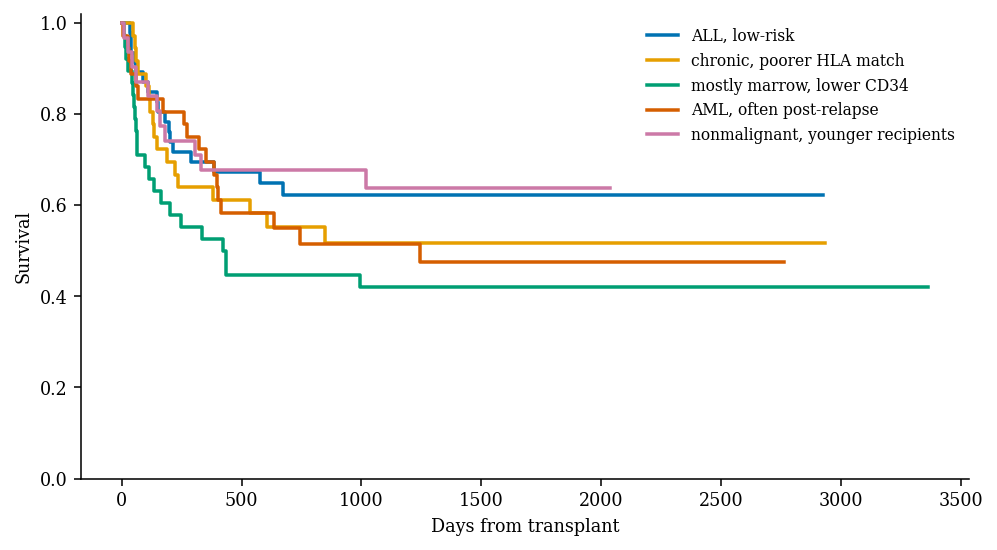

In [7]:
from lifelines import KaplanMeierFitter
from bmt.survival import pairwise_logrank

group_lr = logrank(time, event, pd.Series(labels))
print(f"Log-rank χ² = {group_lr.test_statistic:.2f} on {chosen_k - 1} df, p = {p_text(group_lr.p_value)}")

pairwise = pairwise_logrank(time, event, pd.Series(labels))
pair = pairwise[["level_0", "level_1", "p", "p_bonferroni"]].copy()
pair["p"] = pair["p"].map(p_text)
pair["p_bonferroni"] = pair["p_bonferroni"].map(p_text)
display(pair.rename(columns={
    "level_0": "Group",
    "level_1": "versus",
    "p_bonferroni": "Bonferroni",
}))

colors = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7"]
fig, ax = plt.subplots(figsize=(7.2, 4.0))
for cluster in range(chosen_k):
    part = df.iloc[np.where(labels == cluster)[0]]
    KaplanMeierFitter().fit(
        part["survival_time"],
        part["survival_status"],
        label=names[cluster],
    ).plot_survival_function(ax=ax, ci_show=False, color=colors[cluster], linewidth=1.8)
ax.set_xlabel("Days from transplant")
ax.set_ylabel("Survival")
ax.set_ylim(0, 1.02)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()


## Cox model

Eight covariates, about ten events each: recipient age per 5 years, donor age per 10 years, log CD34 dose, malignant disease, high risk, a second transplant, HLA mismatch, and a peripheral-blood graft.

A binary covariate that fails the rank Schoenfeld test at 5% is refit as a stratum. The forest plot keeps the unstratified fit, so every covariate still has a hazard ratio. Training C-index is reported both ways.


,Covariate,p
0,Malignant disease,0.081
1,Donor age (per 10 years),0.213
2,HLA mismatch (8/10 or 7/10),0.034
3,Recipient age (per 5 years),0.545
4,High risk,0.618
5,Peripheral-blood stem cells,0.330
6,Second transplant after relapse,0.078
7,log CD34+ dose (per kg),0.703


,Covariate,HR,Low,High,p
0,Recipient age (per 5 years),1.33,1.04,1.70,0.024
1,Donor age (per 10 years),1.13,0.87,1.48,0.356
2,log CD34+ dose (per kg),0.94,0.66,1.34,0.743
3,Malignant disease,0.90,0.46,1.77,0.764
4,High risk,1.33,0.79,2.24,0.289
5,Second transplant after relapse,1.06,0.54,2.09,0.868
6,HLA mismatch (8/10 or 7/10),0.93,0.50,1.75,0.830
7,Peripheral-blood stem cells,0.70,0.37,1.31,0.266


Stratum: HLAmismatch
Training C-index: 0.613 unstratified, 0.633 with the stratum
Age HR after the stratum: 1.33, p = 0.024


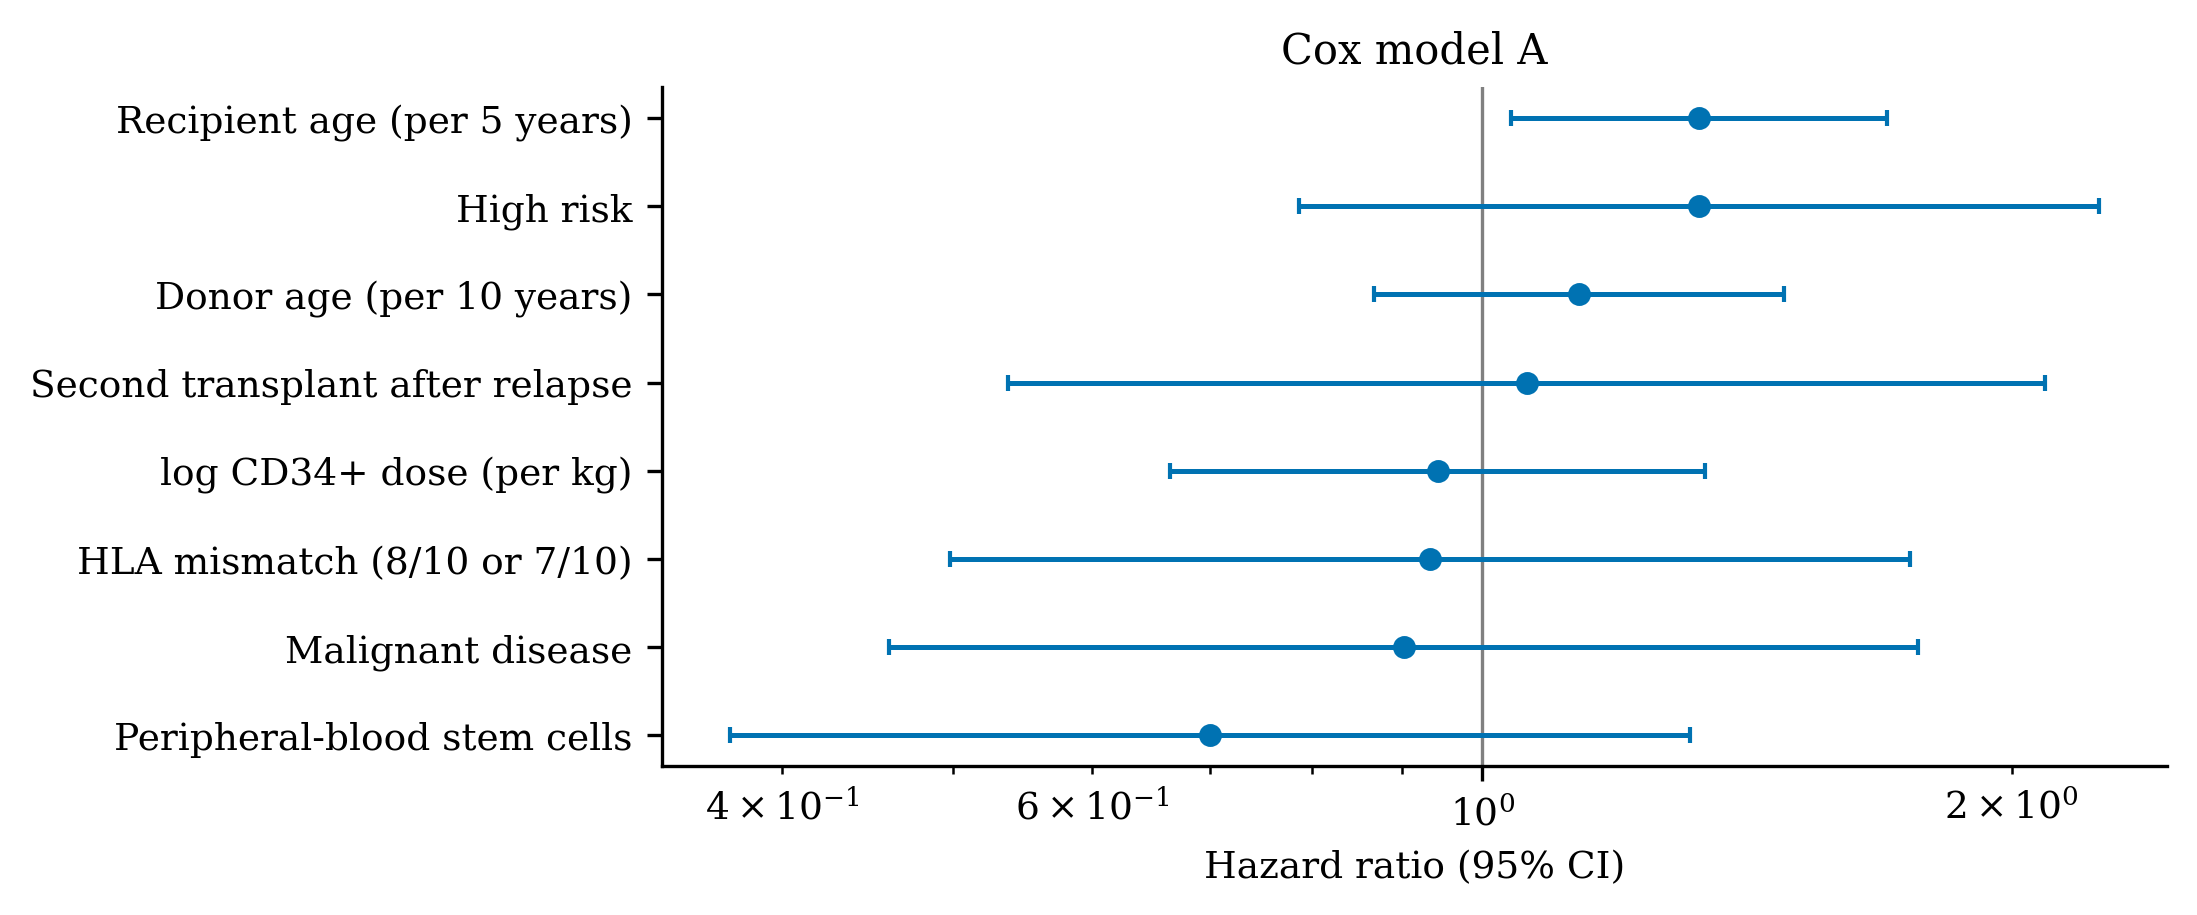

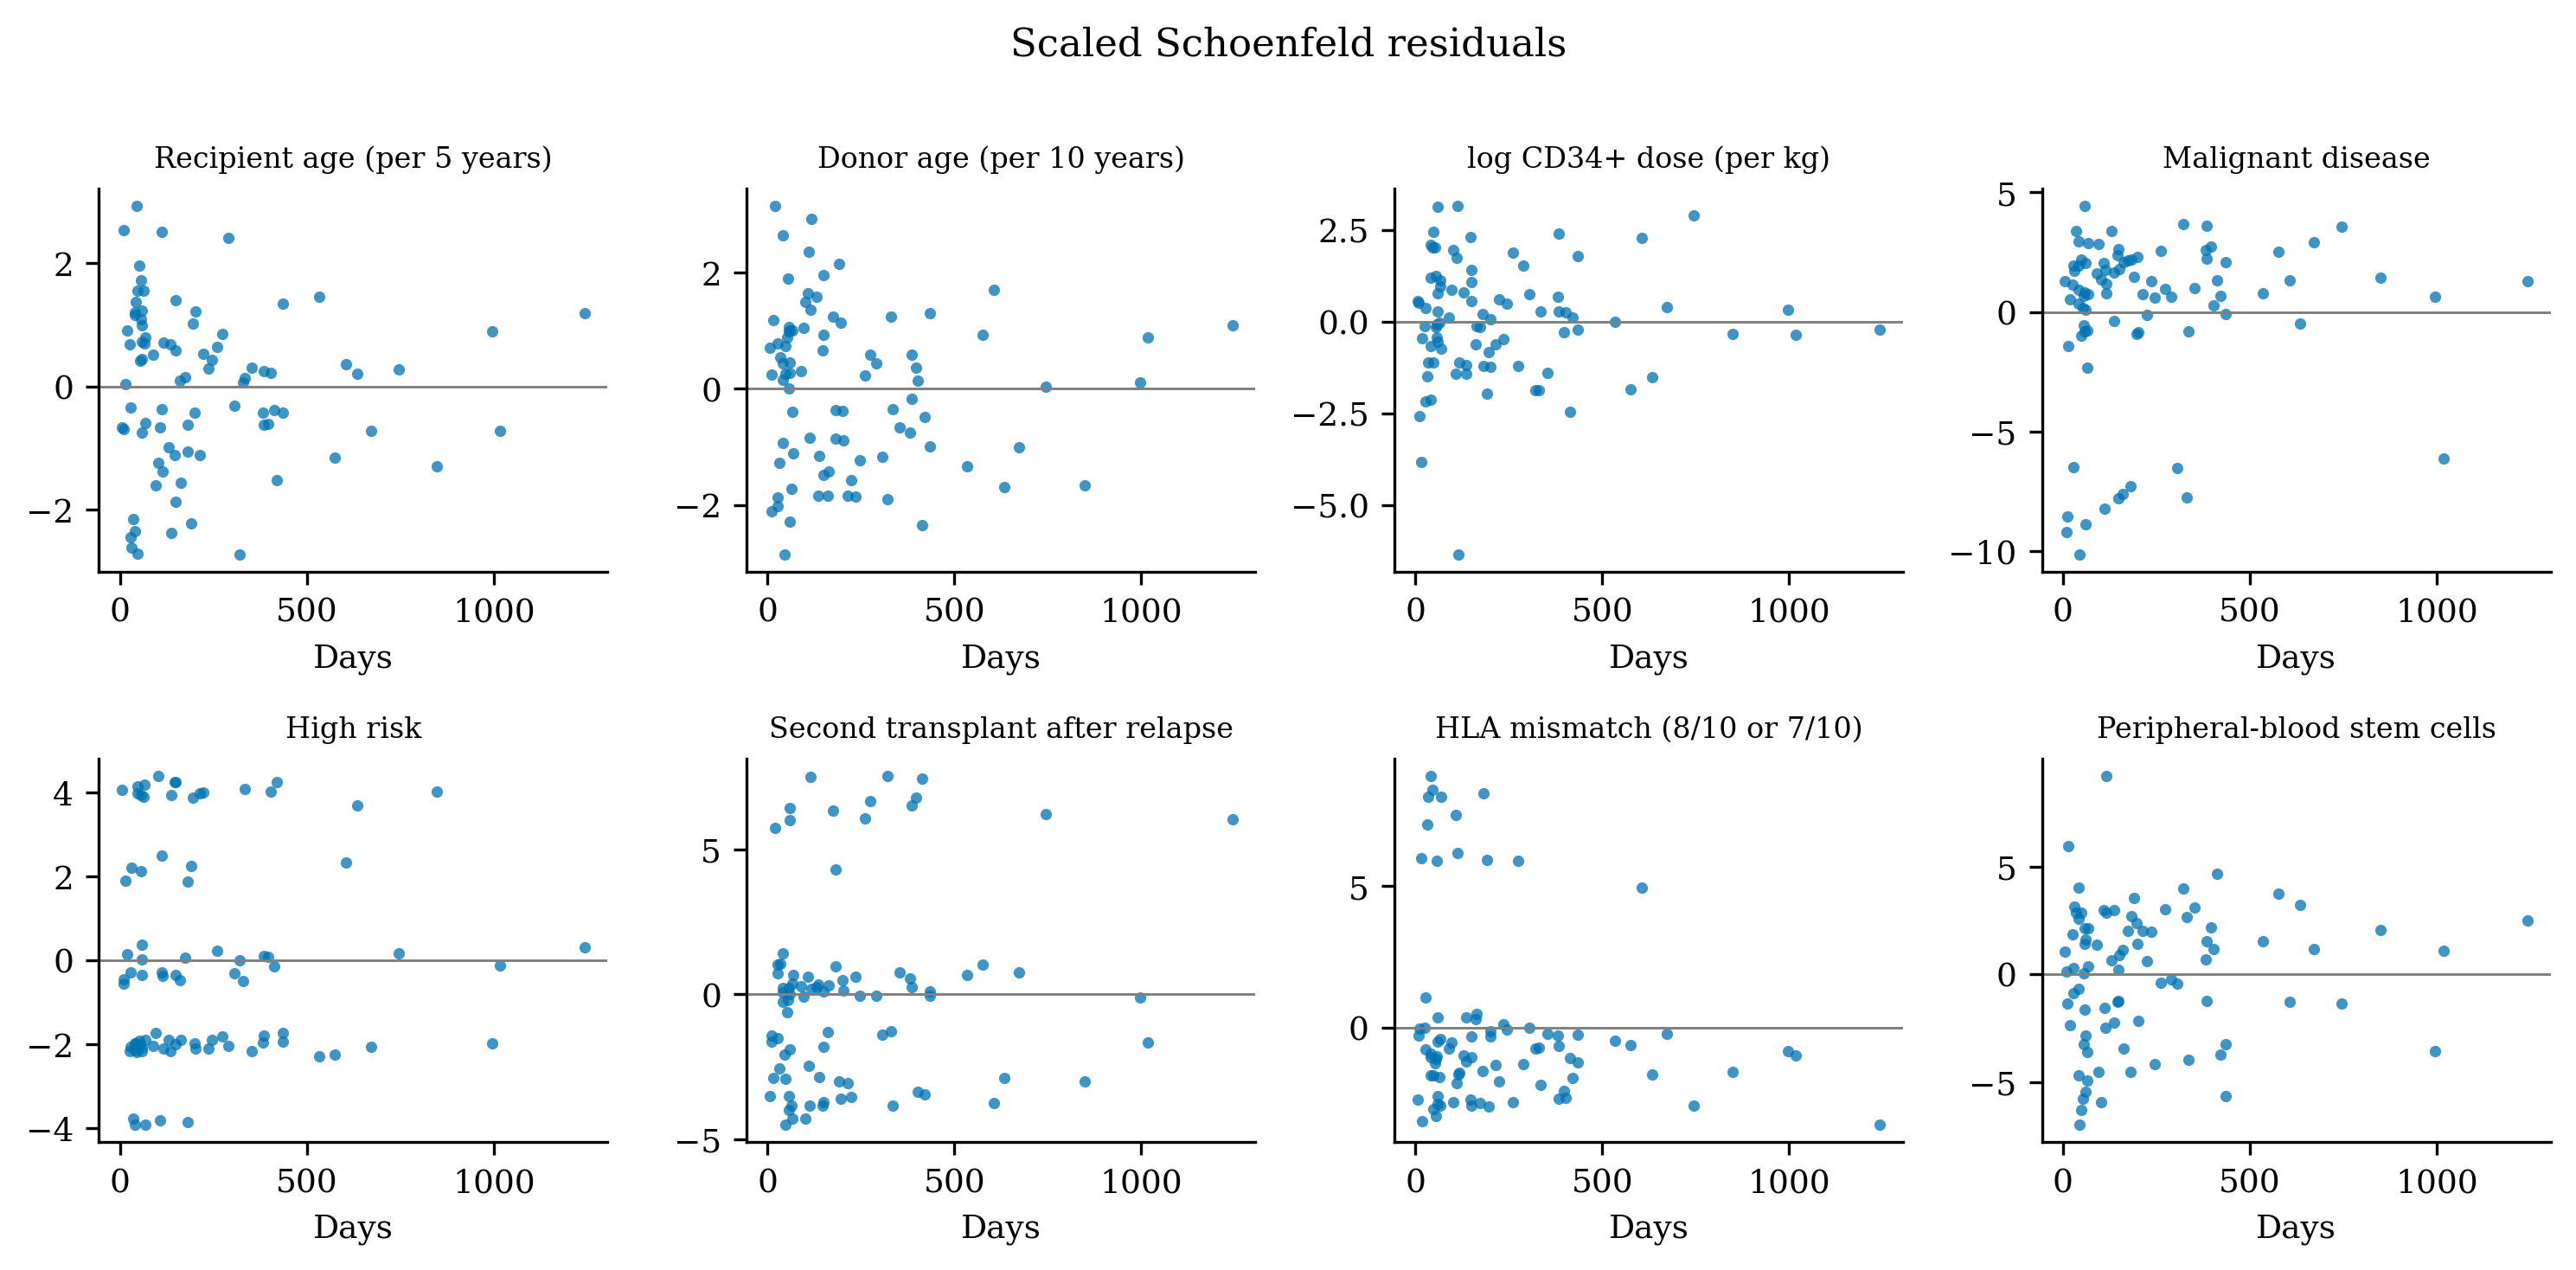

In [8]:
from bmt.features import COX_BINARY
from bmt.plots import plot_fig3, plot_schoenfeld
from bmt.survival import cox_summary_frame, fit_cox, ph_test, survival_design, train_cindex, violating_covariates


def hazard_table(summary, labels_map):
    out = summary[["covariate", "exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].copy()
    out["covariate"] = out["covariate"].map(lambda name: labels_map.get(name, name))
    for col in ("exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%"):
        out[col] = out[col].map(lambda v: f"{v:.3g}" if v < 0.05 or v >= 10 else f"{v:.2f}")
    out["p"] = out["p"].map(p_text)
    return out.rename(columns={
        "covariate": "Covariate",
        "exp(coef)": "HR",
        "exp(coef) lower 95%": "Low",
        "exp(coef) upper 95%": "High",
    })


design_a = survival_design(cox_imputed, df)
model_a_unstrat, pen_unstrat = fit_cox(design_a, penalizer=0.0)
ph = ph_test(model_a_unstrat, design_a)
strata = violating_covariates(ph, COX_BINARY, alpha=0.05)

pen_a = pen_unstrat
model_a = model_a_unstrat
if strata:
    model_a, pen_a = fit_cox(design_a, penalizer=0.0, strata=strata)

summary_a = cox_summary_frame(model_a_unstrat)
summary_final = cox_summary_frame(model_a)

ph_view = ph[["covariate", "p"]].copy()
ph_view["covariate"] = ph_view["covariate"].map(lambda name: COX_LABELS.get(name, name))
ph_view["p"] = ph_view["p"].map(p_text)
display(ph_view.rename(columns={"covariate": "Covariate"}))
display(hazard_table(summary_a, COX_LABELS))

print("Stratum:", ", ".join(strata) if strata else "none")
print(
    f"Training C-index: {train_cindex(model_a_unstrat):.3f} unstratified, "
    f"{train_cindex(model_a):.3f} with the stratum"
)
age = summary_final.set_index("covariate").loc["Recipientage_per5"]
print(f"Age HR after the stratum: {age['exp(coef)']:.2f}, p = {p_text(age['p'])}")

plot_fig3(summary_a, ROOT / "figures" / "fig3_forest.pdf")
display(Image(filename=str(ROOT / "figures" / "fig3_forest.png"), width=680))

residuals = model_a_unstrat.compute_residuals(design_a, kind="scaled_schoenfeld")
plot_schoenfeld(residuals, time, ROOT / "figures" / "schoenfeld.pdf")
display(Image(filename=str(ROOT / "figures" / "schoenfeld.png"), width=760))


## Adding the groups

Model B adds a coefficient for each group except the largest, which is the reference. Group 4 is exactly the nonmalignant patients, so those two coefficients are one contrast and are not listed separately. The likelihood-ratio test is the comparison.

The cross-validated C-index refits the median imputer inside each fold. Model C is a ridge Cox model on the scaled clustering matrix, penalizer 0.1. It is only a sign check against model A. The dashed curves on the last figure are the mean model-A survival inside each group, from the stratified fit.


Reference group: 0, ALL, low-risk
Likelihood-ratio test, B against A: χ² = 6.76 on 4 df, p = 0.149


Cross-validated C-index, A: 0.560 (SD 0.044); folds 0.587, 0.576, 0.585, 0.571, 0.482
Cross-validated C-index, B: 0.534 (SD 0.037)


,Covariate,Model A,Model C,Agree
0,Recipient age (per 5 years),+,+,yes
1,Donor age (per 10 years),+,+,yes
2,log CD34+ dose (per kg),−,−,yes
3,High risk,+,+,yes
4,Second transplant after relapse,+,+,yes
5,Peripheral-blood stem cells,−,−,yes
6,Malignant disease,−,−,yes


Model C training C-index: 0.637


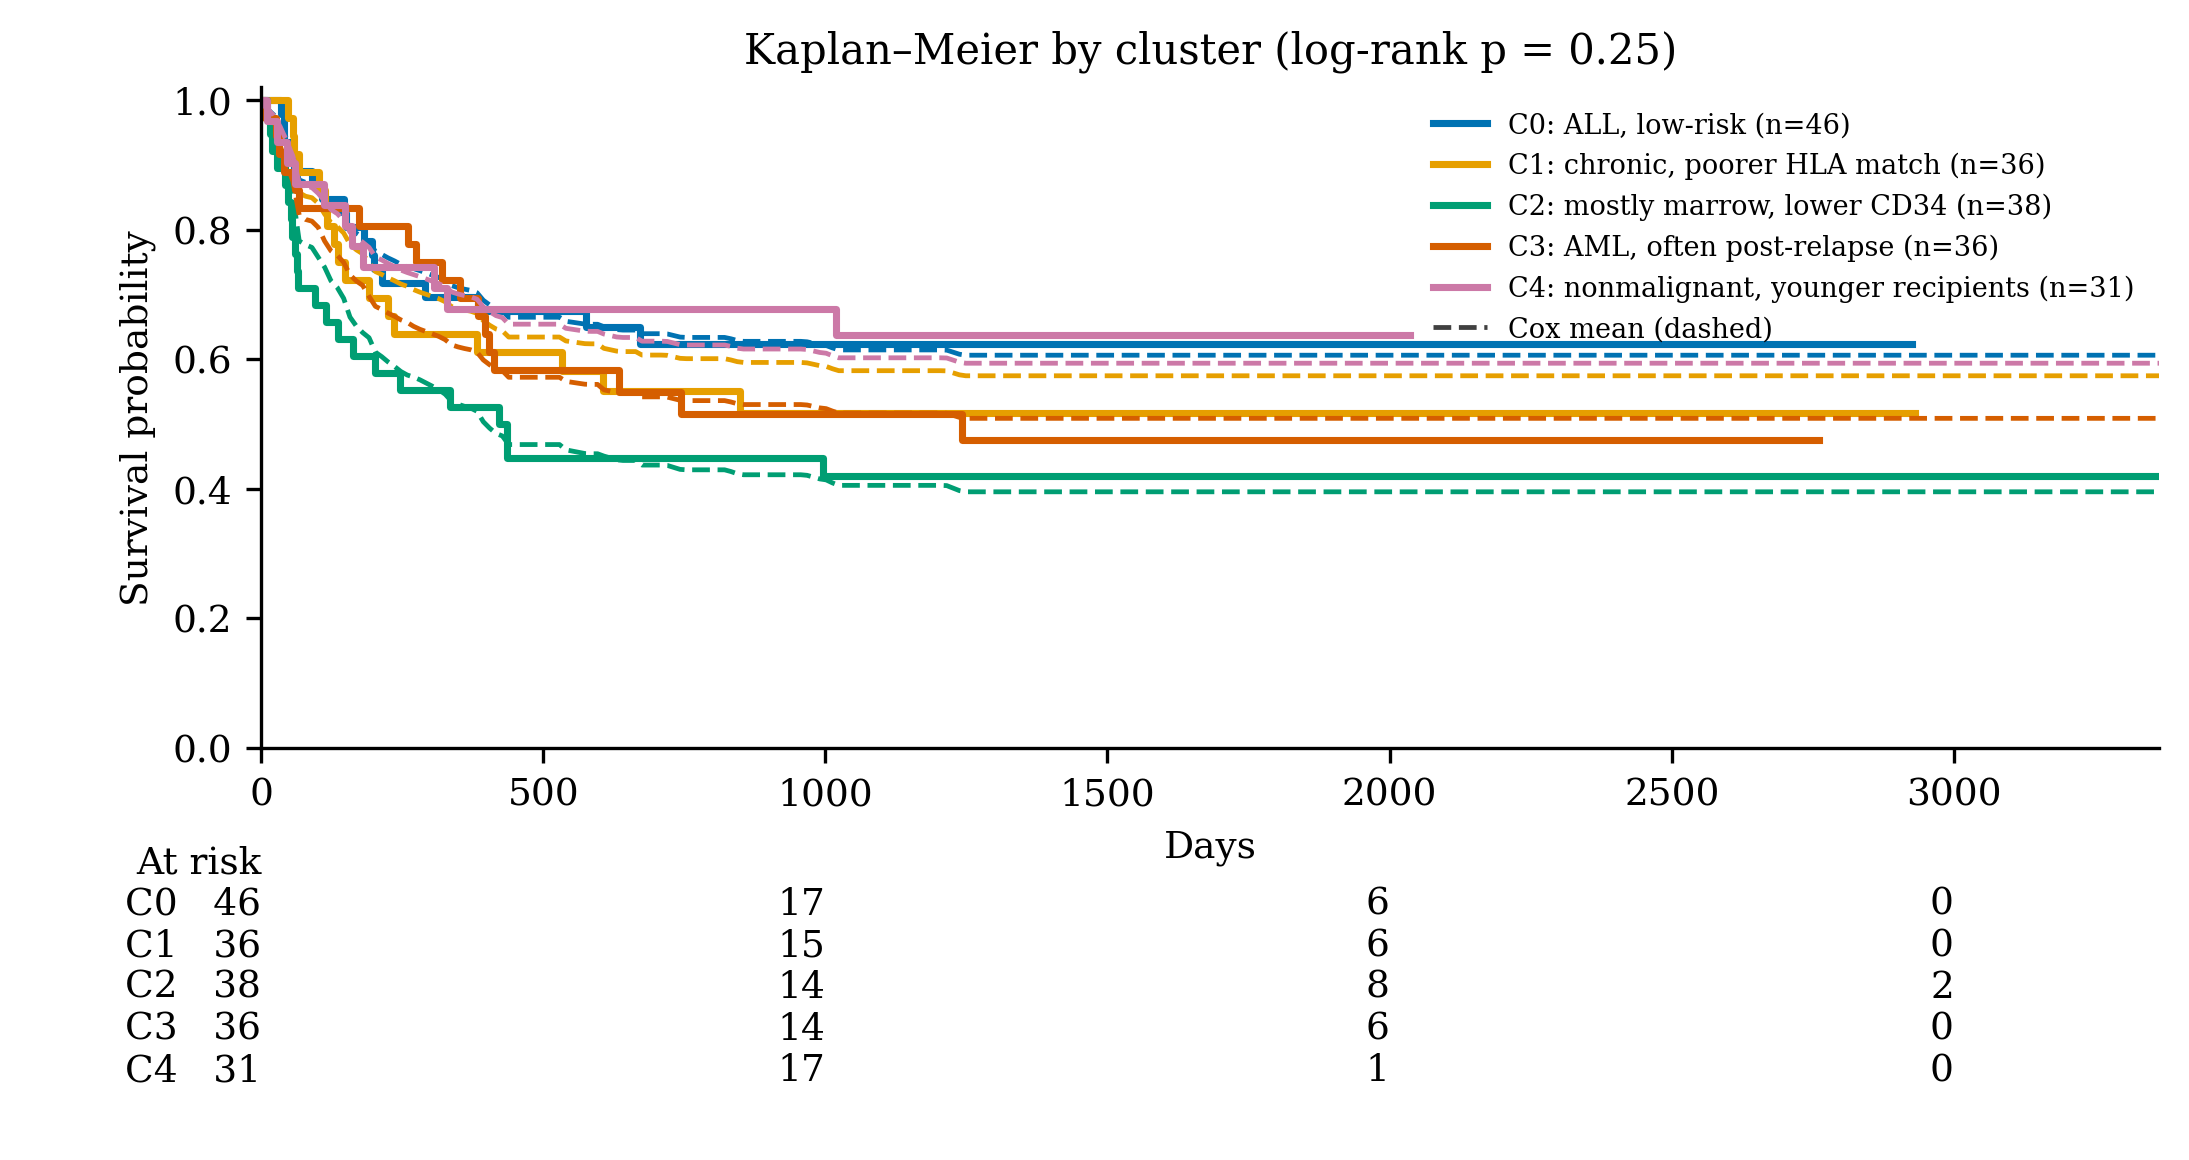

In [9]:
from bmt.plots import plot_fig2
from bmt.survival import (
    cv_cindex,
    likelihood_ratio_test,
    mean_survival_by_cluster,
    prepare_model_b_frame,
    sign_comparison,
)

cov_b, design_b, reference = prepare_model_b_frame(cox_imputed, df, labels)
if strata:
    for column in strata:
        if column not in design_b.columns:
            design_b[column] = design_a[column].to_numpy()

model_b, pen_b = fit_cox(design_b, penalizer=0.0, strata=strata or None)
extra = int(cov_b.shape[1] - cox_imputed.shape[1])
lrt = likelihood_ratio_test(model_a, model_b, df_extra=extra)
print(f"Reference group: {reference}, {names[reference]}")
print(
    f"Likelihood-ratio test, B against A: χ² = {lrt['lr_stat']:.2f} "
    f"on {lrt['df']} df, p = {p_text(lrt['p'])}"
)

cv_a = cv_cindex(cox_imputed, df, penalizer=pen_a or 0.0, strata=strata or None)
cv_b = cv_cindex(cov_b, df, penalizer=pen_b or 0.0, strata=strata or None)
folds_a = ", ".join(f"{v:.3f}" for v in cv_a["folds"])
print(f"Cross-validated C-index, A: {cv_a['mean']:.3f} (SD {cv_a['std']:.3f}); folds {folds_a}")
print(f"Cross-validated C-index, B: {cv_b['mean']:.3f} (SD {cv_b['std']:.3f})")

design_c = survival_design(scaled.reset_index(drop=True), df)
model_c, _ = fit_cox(design_c, penalizer=0.1, l1_ratio=0.0)
signs = sign_comparison(model_a_unstrat, model_c)
sign_view = signs[["model_a", "sign_a", "sign_c_aligned", "agree"]].copy()
sign_view["model_a"] = sign_view["model_a"].map(lambda name: COX_LABELS.get(name, name))
sign_view["sign_a"] = sign_view["sign_a"].map(lambda v: "+" if v > 0 else "−")
sign_view["sign_c_aligned"] = sign_view["sign_c_aligned"].map(lambda v: "+" if v > 0 else "−")
sign_view["agree"] = sign_view["agree"].map(lambda v: "yes" if v else "no")
display(sign_view.rename(columns={
    "model_a": "Covariate",
    "sign_a": "Model A",
    "sign_c_aligned": "Model C",
    "agree": "Agree",
}))
print(f"Model C training C-index: {train_cindex(model_c):.3f}")

times = np.linspace(0, float(time.max()), 300)
curves = mean_survival_by_cluster(model_a, cox_imputed, labels, times)
plot_fig2(
    time, event, labels, names, curves, float(group_lr.p_value),
    ROOT / "figures" / "fig2_km_cox.pdf",
)
display(Image(filename=str(ROOT / "figures" / "fig2_km_cox.png"), width=860))


## For the report

The five groups mostly recover diagnosis and graft source. The marrow group has the lower CD34 dose (median 2.9, against about 10 to 16) and the lower Kaplan–Meier curve (median 421 days). The log-rank test is χ² = 5.41 on 4 degrees of freedom, p = 0.25. Groups 0 and 2 differ at p = 0.049 before correction and p = 0.49 after Bonferroni.

Recipient age is the multivariable association whose interval excludes 1: HR 1.33 per 5 years (1.04 to 1.70). Log CD34 dose is HR 0.94, p = 0.74. HLA mismatch fails proportional hazards (p = 0.034); using it as a stratum leaves the age result in place. The training C-index is 0.61, or 0.63 with that stratum. The five-fold C-index is 0.56 (SD 0.04).

Adding the groups gives a likelihood-ratio χ² of 6.76 on 4 degrees of freedom, p = 0.15, and a cross-validated C-index of 0.53. The ridge model agrees in sign with model A. DBSCAN finds one cluster. The CD34 association appears in the univariate screen and is carried by the same contrast as marrow versus peripheral blood.
